In [16]:
import numpy as np
import matplotlib.pyplot as plt
import warnings

def local_action(path, tau, x, m_tilde, omega_tilde):
    N_tau = len(path)

    # Every site needs two neighbours but the array only has indicies from
    # 0 to N_tau-1, so the two ends would run off the array
    # the %N wraps the values around so the periodic boundary conditions are satisfied
    left = path[(tau - 1) % N_tau]
    right = path[(tau + 1) % N_tau]

    kinetic = (m_tilde / (2) 
               * ((x - left)**2 + (right - x)**2))

    potential = ( 0.5 * m_tilde * (omega_tilde**2) * (x**2))
    
    return kinetic + potential

def metropolis_sweep(path):
   
    #for every lattice site:
    #choose a site               (1)
    #propose a new x             (2)
    #calculate ΔS                (3)
    #decide whether to accept    (4)

    acceptance = 0
    N_tau = len(path) #define number of elements in time lattice

    for i in range(N_tau):
        tau = np.random.randint(N_tau) #(1), choosing random site to start at
        #tau = i #option for going through systematically instead of randomly
        j = np.random.uniform(-h,h) #generating the amount to change the site to

        x_old = path[tau] #defining old position in array
        x_new = x_old + j #(2)

        S_old = local_action(path, tau, x_old, m_tilde, omega_tilde)
        S_new = local_action(path, tau, x_new, m_tilde, omega_tilde)

        dS = S_new - S_old #(3)
        if dS <= 0 or np.random.rand() < np.exp(-dS): #(4)
            path[tau] = x_new
            acceptance += 1
                # New values that lower the action are always accepted
                # While those that would increase the action are 
                # accepted with probablity exp(-delta_S)
    acc_rate = acceptance/N_tau

    return path, acc_rate

def naive_error(a):
    return a.std(ddof=1)/np.sqrt(len(a))

def integrated_auto_correlation(a, c=5):

    a = np.asarray(a) - np.mean(a) #ensuring series is centered (mean = 0)

    N = len(a)
    var = np.mean(a**2)
    max_lag = N//2

    #C(L) is the correlation between two measurements that are L sweeps apart
    #must be computed one at a time
    C = np.zeros(max_lag)

    if not np.isfinite(var) or var<=0:
        raise ValueError(
            "The series has zero or invalid variance;" 
            "autocorrelation time cannot be estimated"
        )
    # a[:N-lag] is the series with the last entry chopped off
    # a[lag:] is the series with the first entry chopped off]
    for lag in range(max_lag):
        C[lag] = np.mean(a[:N-lag]*a[lag:]) / var

    A = np.cumsum(C[1:])

    tau_path = 1/2 + A

    #we will use Sokal's cutoff criterion to ensure that once the error reduces into noise we stop itnegrating 
    for W in range(1, len(tau_path) + 1):
        tau_int = tau_path[W-1]
        if W >= c*tau_int:
            return tau_int, W, C, tau_path

    warnings.warn(
        "Sokal window criterion did not close." \
        "The autocorrelation estimate may be unreliable;" 
        "consider running more sweeps.",
        RuntimeWarning
    )

    #what to return if the window never closed due to not enough sweeps 
    return tau_path[-1], max_lag, C, tau_path

def correlation(S):
    S = np.array(S)
    N_sweeps_local, N_tau_local = np.shape(S)

    if S.shape[1] != N_tau:
        raise ValueError("Expected a 2D array with N_tau columns")

    C = np.zeros(N_tau_local)

    for n in range(N_tau_local):
        C[n] = np.mean(S * np.roll(S, -n, axis=1)) - S.mean()**2
    return C

def jackknife(S, B, statistic):
    S = np.array(S)
    N = len(S)

    remainder = N % B
    if remainder != 0:
        S = S[remainder:]
        N = len(S)

    N_blocks = N // B
    if N_blocks < 2:
        raise ValueError('Need at least 2 blocks.')
    
    estimates_j = []
    estimate = statistic(S)

    for i in range(N_blocks):
        start = i * B
        end = start + B

        S_leave_out = np.concatenate((S[:start], S[end:]), axis=0)
        estimates_j.append(statistic(S_leave_out))
    
    estimates_j = np.array(estimates_j)

    mean_j = estimates_j.mean(axis=0)
    var_j = (N_blocks - 1) / N_blocks * np.sum((estimates_j - mean_j)**2, axis=0)
    error_j = np.sqrt(var_j)

    return estimate, error_j

def energy_gap(data):
    c = correlation(data)[:5]
    return - np.log(c[1:] / c[:-1])



In [ ]:
class MonteCarloAnalysis:
    def __init()

Acceptance rate = 0.829842857142857

<x>   = -0.0072 ± 0.0082  (naive 0.0010)       theoretical value within range: True
<x^2> = 0.4457 ± 0.0035  (naive 0.0007)       theoretical value within range: True
tau_int(x)   = 30.79  (W=155),  N_eff = 162
tau_int(x^2) = 12.02  (W=61),  N_eff = 416
<x> is 0.88 true standard errors from 0
<x^2> is -0.42 true standard errors from the analytical value 0.447


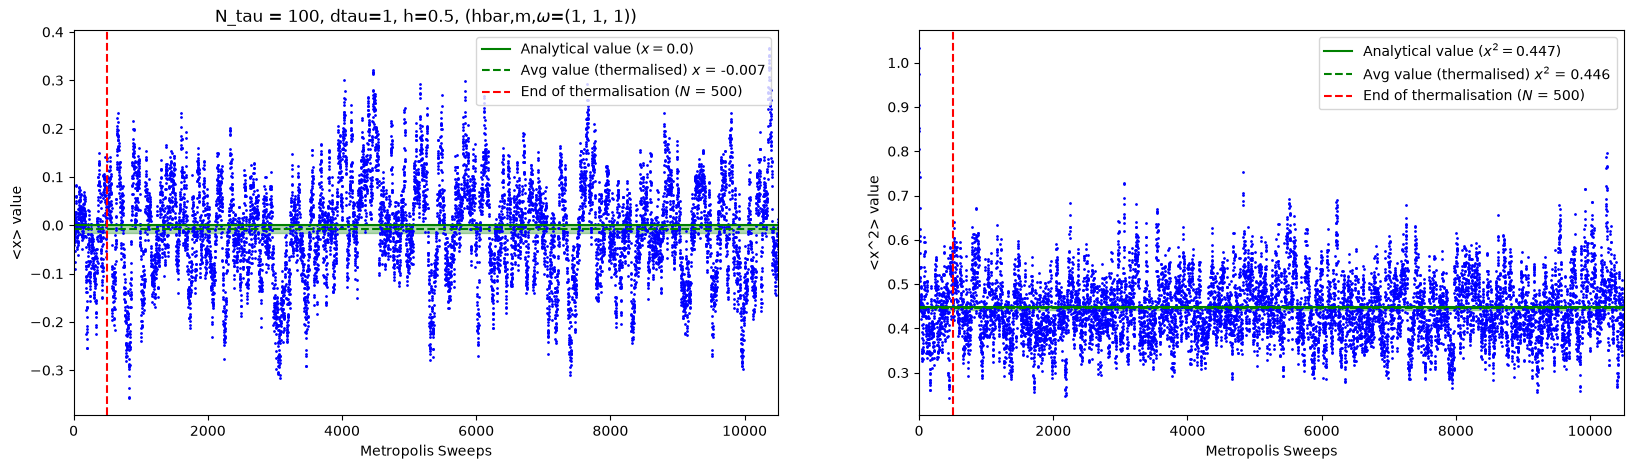

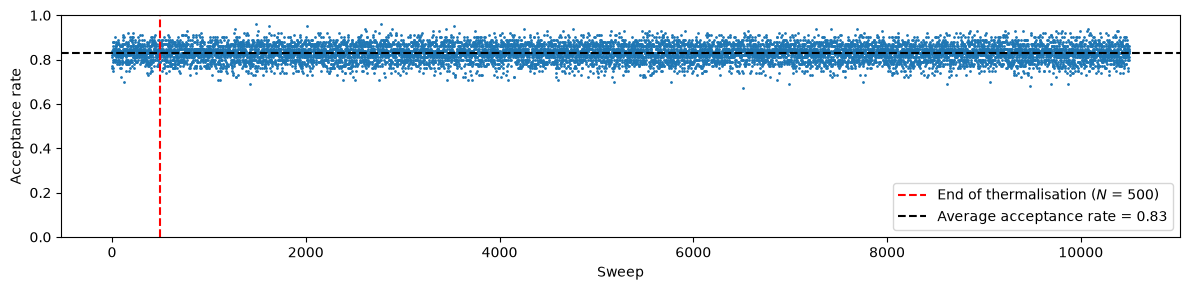

In [2]:
#Defining Parameters
h = 0.5 #step size

m = 1
omega = 1
hbar = 1

N_tau = 100 #size of the lattice
delta_tau = 1

m_tilde  = m * delta_tau #ensuring dimensionless varianbles
h_tilde = hbar * delta_tau 
omega_tilde = omega * delta_tau

N_therm = 500 #how many of the first sweeps are discarded
N_sweeps = 10000 #how many passes are repeated
samples = [] # for calculating the wavefunction

#Initialising
x = []
x_2 = []
x_analytical = 0.0
#x_2_analytical = hbar / (2*m*omega) * (1 / np.tanh(beta*hbar*omega/2)) #should be roughly equivalent to 0.5

R = 1 + (omega_tilde**2/2) - omega_tilde*(np.sqrt(1+omega_tilde**2/4))

x_2_analytical = (1 / (2*m_tilde*omega_tilde*np.sqrt(1+omega_tilde**2/4))) * ((1+R**(N_tau))/(1-R**N_tau))

path = np.random.randn(N_tau)
total_acc_rate = []

#Running Metropolis-Hastings Algorithm
for i in range(N_therm + N_sweeps):
    total_path, acc_rate = metropolis_sweep(path)
    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))
    total_acc_rate.append(acc_rate)
    if i >= N_therm:
        samples.append(total_path.copy())

# Slicing to get rid of first N_therm sweeps for thermalisation
x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])
total_acc_rate = np.array(total_acc_rate)

x_mean, x_naive_error = np.mean(x_thermalised), naive_error(x_thermalised)
x_2_mean, x_2_naive_error = np.mean(x_2_thermalised), naive_error(x_2_thermalised)
tau_x,  W_x,  C_x,  tau_run_x  = integrated_auto_correlation(x_thermalised)
tau_x_2, W_x_2, C_x_2, tau_run_x_2 = integrated_auto_correlation(x_2_thermalised)

#2*tau=1+2*A
x_true_error = x_naive_error * np.sqrt(2*tau_x) 
x_2_true_error = x_2_naive_error * np.sqrt(2*tau_x_2)

x_truth_value = (x_mean - x_true_error <= 0 <= x_mean + x_true_error)
x_2_truth_value = (x_2_mean - x_2_true_error <= x_2_analytical <= x_2_mean + x_2_true_error)

print(f"Acceptance rate = {np.mean(total_acc_rate)}")
print("")
print(f"<x>   = {x_mean:.4f} ± {x_true_error:.4f}  (naive {x_naive_error:.4f}) \
      theoretical value within range: {x_truth_value}")
print(f"<x^2> = {x_2_mean:.4f} ± {x_2_true_error:.4f}  (naive {x_2_naive_error:.4f}) \
      theoretical value within range: {x_2_truth_value}")
print(f"tau_int(x)   = {tau_x:.2f}  (W={W_x}),  N_eff = {N_sweeps/(2*tau_x):.0f}")
print(f"tau_int(x^2) = {tau_x_2:.2f}  (W={W_x_2}),  N_eff = {N_sweeps/(2*tau_x_2):.0f}")
print(f"<x> is {abs(x_mean)/x_true_error:.2f} true standard errors from 0")
print(f"<x^2> is {(x_2_mean - x_2_analytical) / x_2_true_error:.2f} true standard errors from the analytical value {np.round(x_2_analytical, 3)}")

# Expectation values vs. sweeps
sweeps = np.arange(len(x))
fig, ax = plt.subplots(1, 2, figsize=(20,5))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=1)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<x> value")
#ax[0].set_ylim(-0.25, 0.25)
ax[0].set_xlim(0, N_therm + N_sweeps)
ax[0].axhline(y=x_analytical, color='g', linestyle='-', label = f"Analytical value ($x={x_analytical}$)")
ax[0].axhline(y=np.mean(x_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x$ = {np.round(np.mean(x_thermalised), decimals=3)}")
ax[0].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[0].set_title(rf"N_tau = {N_tau}, dtau={delta_tau}, h={h}, (hbar,m,$\omega$={hbar, m, omega})")
ax[0].legend()

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=1)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel("<x^2> value")
#ax[1].set_ylim(0.4, 0.6)
ax[1].set_xlim(0, N_therm + N_sweeps)
ax[1].axhline(y=x_2_analytical, color='g', linestyle='-', label = f"Analytical value ($x^2={np.round(x_2_analytical, 3)}$)")
ax[1].axhline(y=np.mean(x_2_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x^2$ = {np.round(np.mean(x_2_thermalised), decimals=3)}")
ax[1].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[1].legend()

#error bands
ax[0].axhspan(x_mean - x_true_error, x_mean + x_true_error, color="green", alpha=0.3)
ax[1].axhspan(x_2_mean - x_2_true_error, x_2_mean + x_2_true_error, color="green", alpha=0.3)

# Acceptance rate
plt.figure(figsize=(12,3))
plt.plot(total_acc_rate, '.', markersize=2)
plt.axvline(N_therm, color='red', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
plt.axhline(np.mean(total_acc_rate), linestyle='--', color='black', label=f"Average acceptance rate = {np.round(np.mean(total_acc_rate), decimals=3)}")
plt.ylim(0,1)
plt.xlabel("Sweep")
plt.ylabel("Acceptance rate")
plt.legend()

plt.tight_layout()
plt.show()


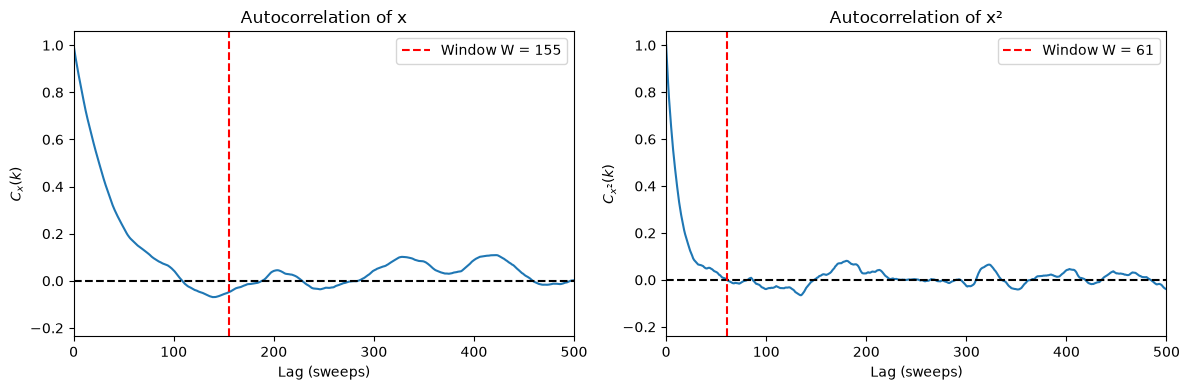

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(np.arange(len(C_x)), C_x)
ax[0].axhline(0, color="black", linestyle="--")
ax[0].axvline(W_x, color="red", linestyle="--",
              label=f"Window W = {W_x}")
ax[0].set_xlabel("Lag (sweeps)")
ax[0].set_ylabel(r"$C_x(k)$")
ax[0].set_xlim(0, 500)
ax[0].set_title("Autocorrelation of x")
ax[0].legend()

ax[1].plot(np.arange(len(C_x_2)), C_x_2)
ax[1].axhline(0, color="black", linestyle="--")
ax[1].axvline(W_x_2, color="red", linestyle="--", label=f"Window W = {W_x_2}")
ax[1].set_xlim(0, 500)
ax[1].set_xlabel("Lag (sweeps)")
ax[1].set_ylabel(r"$C_{x^2}(k)$")
ax[1].set_title("Autocorrelation of x²")
ax[1].legend()

plt.tight_layout()
plt.show()

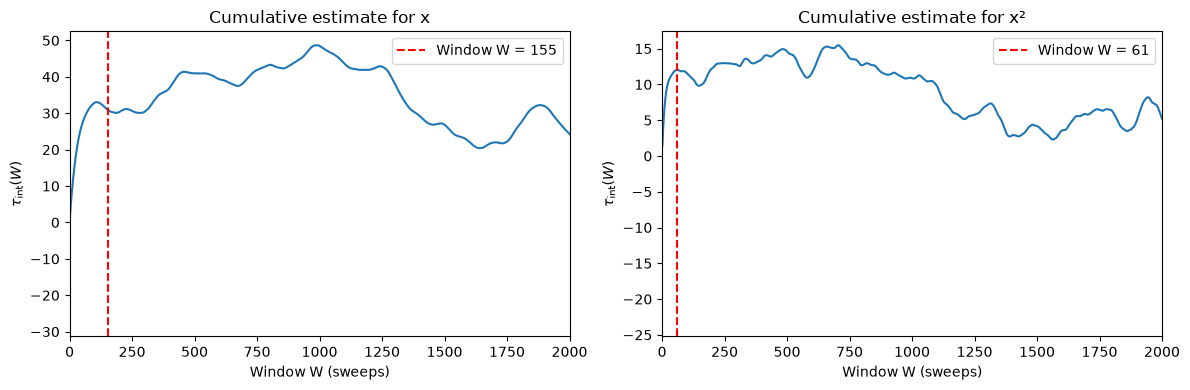

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(np.arange(1, len(tau_run_x) + 1),tau_run_x)
ax[0].axvline(W_x, color="red", linestyle="--", label=f"Window W = {W_x}")
ax[0].set_xlabel("Window W (sweeps)")
ax[0].set_xlim(0, 2000)
ax[0].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[0].set_title("Cumulative estimate for x")
ax[0].legend()

ax[1].plot(np.arange(1, len(tau_run_x_2) + 1), tau_run_x_2)
ax[1].axvline(W_x_2, color="red", linestyle="--", label=f"Window W = {W_x_2}")
ax[1].set_xlabel("Window W (sweeps)")
ax[1].set_xlim(0, 2000)
ax[1].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[1].set_title("Cumulative estimate for x²")
ax[1].legend()

plt.tight_layout()
plt.show()


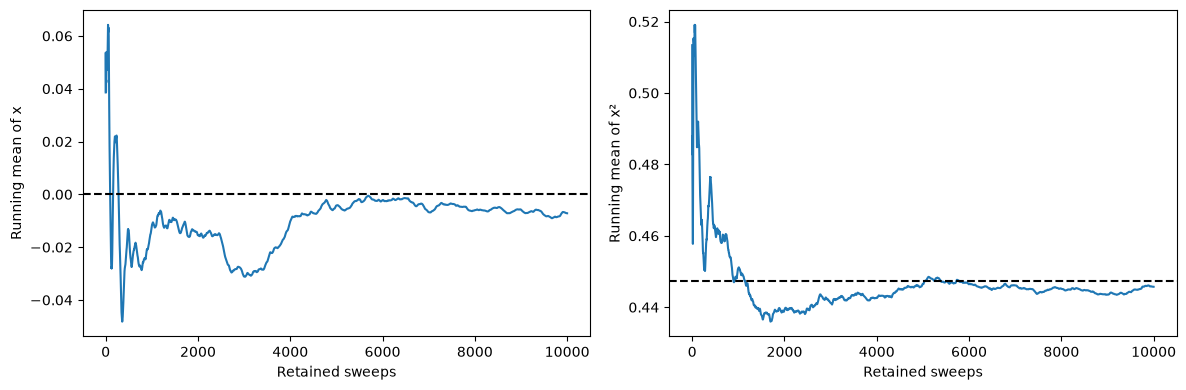

In [5]:
x_thermalised = np.asarray(x[N_therm:])
x2_thermalised = np.asarray(x_2[N_therm:])

running_x = np.cumsum(x_thermalised) / np.arange(
    1, len(x_thermalised) + 1
)

running_x2 = np.cumsum(x2_thermalised) / np.arange(
    1, len(x2_thermalised) + 1
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(running_x)
ax[0].axhline(0, linestyle="--", color="black")
ax[0].set_xlabel("Retained sweeps")
ax[0].set_ylabel("Running mean of x")

ax[1].plot(running_x2)
ax[1].axhline(x_2_analytical, linestyle="--", color="black")
ax[1].set_xlabel("Retained sweeps")
ax[1].set_ylabel("Running mean of x²")

plt.tight_layout()
plt.show()

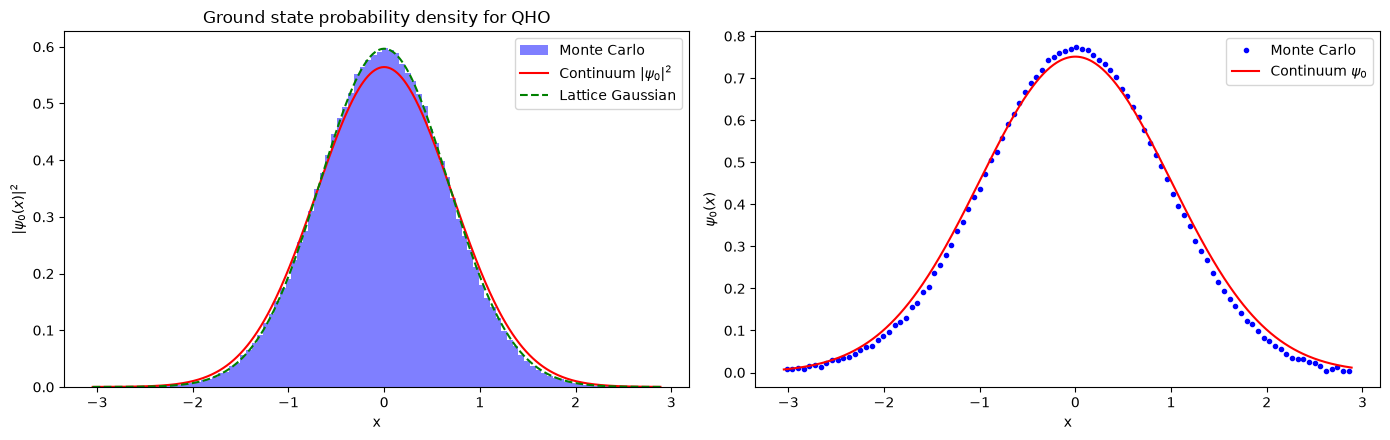

In [6]:
#continuum ground state
samples_gs = np.concatenate(samples)

x_wavefn = np.linspace(samples_gs.min(), samples_gs.max(), 500)
# continuum |psi_0|^2
psi2_cont = np.sqrt(m*omega/(np.pi*hbar)) * np.exp(-m*omega*x_wavefn**2/hbar)

#lattice-exact ground state
sigma2 = x_2_analytical
psi2_latt = np.exp(-1*(x_wavefn**2)/(2*sigma2)) / np.sqrt(2*np.pi*sigma2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# |psi|^2
ax[0].hist(samples_gs, bins=100, density=True, alpha=0.5, color="blue", label="Monte Carlo")
ax[0].plot(x_wavefn, psi2_cont, 'r-',  label=r"Continuum $|\psi_0|^2$")
ax[0].plot(x_wavefn, psi2_latt, 'g--', label="Lattice Gaussian")
ax[0].set_xlabel("x"); ax[0].set_ylabel(r"$|\psi_0(x)|^2$")
ax[0].set_title("Ground state probability density for QHO")
ax[0].legend()

# psi itself (positive, so it's just the square root of the density)
counts, edges = np.histogram(samples_gs, bins=100, density=True)
centres = 0.5*(edges[1:] + edges[:-1])
ax[1].plot(centres, np.sqrt(counts), 'o', color="blue", markersize=3, label="Monte Carlo")
ax[1].plot(x_wavefn, np.sqrt(psi2_cont), 'r-', label=r"Continuum $\psi_0$")
ax[1].set_xlabel("x"); ax[1].set_ylabel(r"$\psi_0(x)$")
ax[1].legend()

plt.tight_layout()
plt.show()


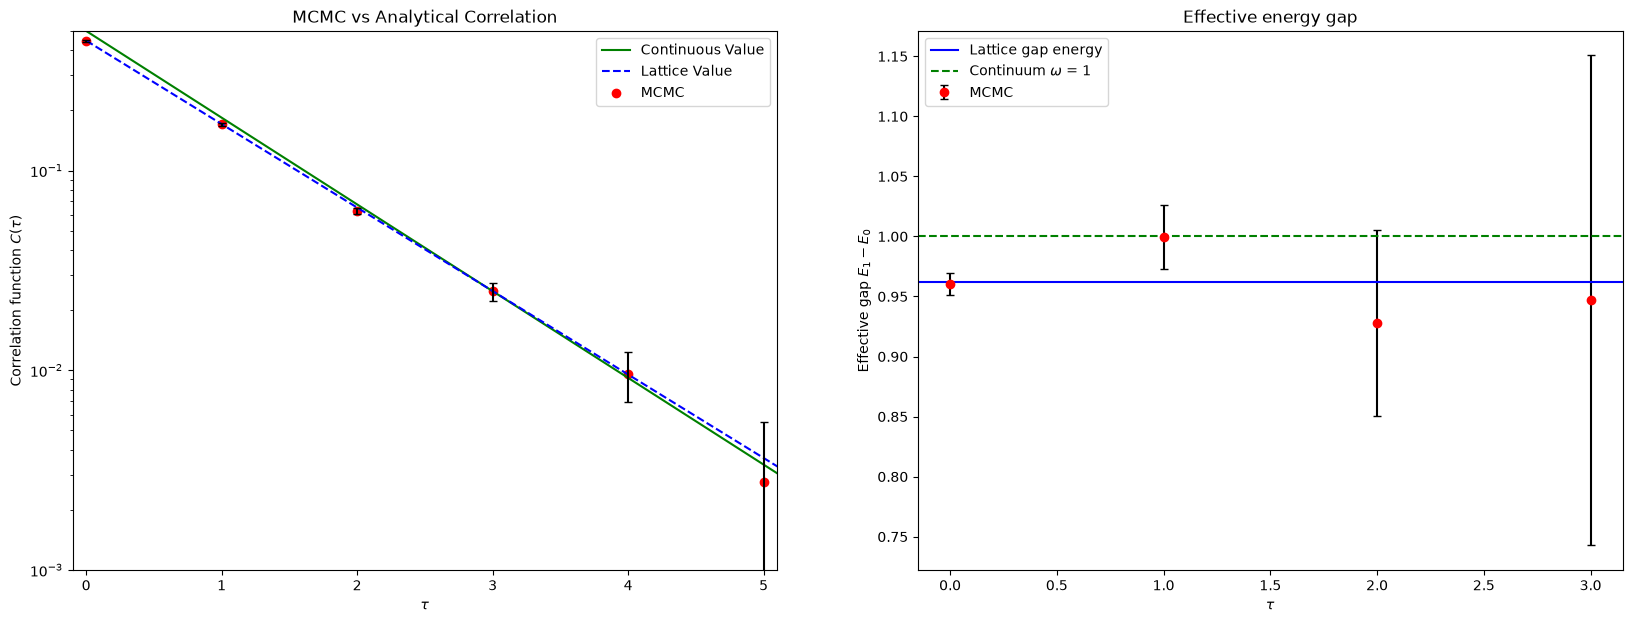

In [19]:
n = np.arange(N_tau)
tau = n * delta_tau
C_cont = (hbar / (2*m_tilde*omega_tilde)) * np.exp(-omega*tau)
C_analytical = (R**n + R**(N_tau-n)) / (2*m_tilde*omega_tilde*np.sqrt(1+omega_tilde**2/4)*(1-R**N_tau))

x_corr, x_corr_err = jackknife(samples, B=500, statistic=correlation)
gap, gap_err = jackknife(samples, B=500, statistic=energy_gap)

#converting energy to physical units
gap, gap_err = gap/delta_tau, gap_err/delta_tau
gap_analytical = -np.log(R)/delta_tau

fig, ax = plt.subplots(1, 2, figsize = (20, 7))
ax[0].plot(tau, C_cont, '-', c='green', label="Continuous Value")
ax[0].plot(tau, C_analytical, '--', c='blue', label="Lattice Value")
ax[0].scatter(tau, x_corr, c='r', label="MCMC")
ax[0].errorbar(tau, x_corr, yerr=x_corr_err, fmt='none', c='black', capsize=3)
ax[0].set_yscale("log")
ax[0].set_xlim(-0.1, 5.1)
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylim(0.001, 0.5)
ax[0].set_ylabel(r"Correlation function $C(\tau)$")
ax[0].set_title("MCMC vs Analytical Correlation")
ax[0].legend()

ax[1].errorbar(np.arange(len(gap)) * delta_tau, gap, yerr=gap_err, fmt='o', c='red', ecolor='black', capsize=3, label="MCMC")
ax[1].axhline(gap_analytical, c='blue', label='Lattice gap energy')
ax[1].axhline(omega, c='green', ls='--', label=rf"Continuum $\omega$ = {omega}")
ax[1].set_xlabel(r"$\tau$")
ax[1].set_ylabel(r"Effective gap $E_1-E_0$")
ax[1].set_title("Effective energy gap")
ax[1].legend()


plt.legend()
plt.show()
